# RetailRocket 电商用户行为与转化分析

## 结果摘要
全量公开数据有 2,756,101 条记录。去除 460 条完全重复记录后，严格顺序浏览→加购率为 2.35%，浏览→购买率为 0.71%。仅使用完整首次观察周和完整随访周，次周活动留存为 3.28%。后续会话转化高于首次观察会话，差异为观察性结果。

## 背景与方法
为数据分析和数据运营实习准备的公开数据个人项目。研究浏览、加购、购买路径，识别值得调查的转化环节。

### 关键假设
- UTC 时间；匿名访客不等于实名账户，首次观察不等于真实新客。
- 完全重复行去重；主漏斗严格递增，可跨会话和商品，另做同商品口径。
- 相邻事件间隔超过 30 分钟开启新会话；同毫秒事件不强行确定先后。
- 留存采用自然周队列，观察不足的单元格不记为零。
- 无收入、投放、实验和人口属性数据；不推断运营提升或因果机制。

原始来源：[RetailRocket / Kaggle](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset)
参考研究问题：[product-funnel-activation-sql](https://github.com/jacobmackey01/product-funnel-activation-sql)
本项目重新编写 SQL、执行原始数据，并增加会话、同商品转化、商品对比和独立校验。


### 1 加载环境与全量数据

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
assert (root / 'sql').exists(), '请从项目根目录或 notebooks 目录运行'
sys.path.insert(0, str(root / 'src'))
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import run_analysis, validate, plot_results
%matplotlib inline
receipt = run_analysis.run(root / 'data/events.csv.gz')
print('已重新执行 SQL，耗时', receipt['seconds'], '秒')
def read(name): return pd.read_csv(root / f'results/tables/{name}.csv')
plot_results.style()


Prepared cleaned events, visitors and sessions


01_quality: 1 result rows


02_funnel: 3 result rows


03_funnel_sensitivity: 3 result rows


04_sessions: 2 result rows


...

06_activation: 1 result rows


07_products: 12 result rows


08_profiles: 4 result rows


09_activity_sensitivity: 2 result rows


已重新执行 SQL，耗时 1.95 秒


## 数据
### 2 审计数据质量

In [2]:
display(read('01_quality').T.rename(columns={0:'值'}))
validation = {'fixtures': validate.fixture_checks(), 'pandas': validate.independent_checks(root/'data/events.csv.gz')}
print(json.dumps(validation,ensure_ascii=False,indent=2))

,值
raw_rows,2756101
invalid_rows,0
exact_duplicates,460
clean_rows,2755641
visitors,1407580
items,235061
orders,17672
first_event_utc,2015-05-03 03:00:04.384
last_event_utc,2015-09-18 02:59:47.788
views,2664218


{
  "fixtures": [
    "same-timestamp order",
    "cart before view",
    "cross-item vs same-item",
    "exact duplicate",
    "30-minute session boundary",
    "immature cohort exclusion"
  ],
  "pandas": {
    "raw_rows": 2756101,
    "clean_rows": 2755641,
    "funnel": [
      1404179,
      32934,
      9952
    ],
    "retention_cells_checked": 169,
    "eligible_7d_visitors": 1348273,
    "buyers_7d": 10165,
    "sessions_checked": 1761675,
    "products_checked": 12
  }
}


## 分析结果
### 3 按时间顺序计算访客漏斗

,stage_order,stage,visitors,prior_visitors,viewing_visitors,prior_conversion_pct,overall_conversion_pct,dropoff_visitors
0,1,view,1404179,NaN,1404179,NaN,100.000,NaN
1,2,cart_after_view,32934,1404179.0,1404179,2.345,2.345,1371245.0
2,3,purchase_after_cart,9952,32934.0,1404179,30.218,0.709,22982.0


,definition,cart_visitors,buyer_visitors
0,strict_cross_item,32934,9952
1,nondecreasing_cross_item,32934,9952
2,strict_same_item,30344,9641


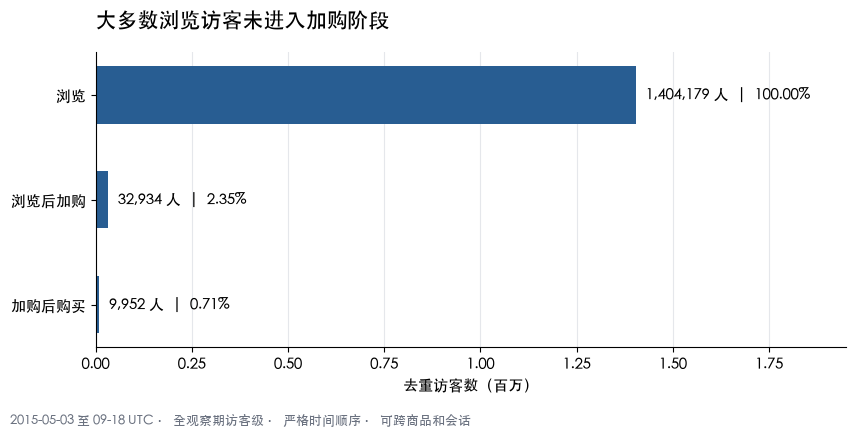

In [3]:
display(read('02_funnel').round(3))
display(read('03_funnel_sensitivity'))
display(plot_results.funnel())
plt.close('all')

同商品严格漏斗购买访客为 9,641 人，低于可跨商品的 9,952 人。加购是所选路径的必要环节，存在直接购买和日志缺失，不能将所有未走完路径的访客解释为购买失败。

### 4 比较首次观察会话与后续会话

,segment,sessions,distinct_visitors,viewing_sessions,ordered_cart_sessions,ordered_buy_sessions,purchasing_sessions,ordered_conversion_pct,any_purchase_pct,mean_viewed_items
0,first_observed,1407580,1407580,1403730,24857,6060,7524,0.432,0.535,1.248
1,returning_observed,354095,181633,352051,11818,4661,6773,1.324,1.913,1.621


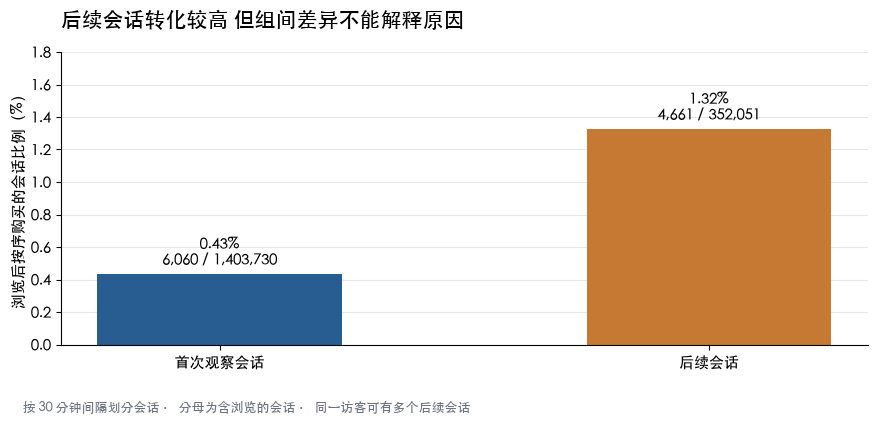

In [4]:
display(read('04_sessions').round(3))
display(plot_results.sessions())
plt.close('all')

首次观察会话按序购买率为 0.43%，后续会话为 1.32%。分组在会话开始时确定；同一访客可贡献多个会话，因此会话不相互独立。差异不能证明回访引起转化提升。

### 5 完整周队列活动留存

,week_age,cohort_size,active_visitors,retention_pct
0,0,1366774,1366774,100.000
1,1,1295569,42465,3.278
2,2,1233240,19923,1.616
3,3,1167907,13798,1.181
4,4,1102643,10670,0.968
5,5,1038352,8704,0.838
6,6,971271,7297,0.751
7,7,898081,6200,0.690
8,8,809820,5325,0.658
9,9,729257,4441,0.609


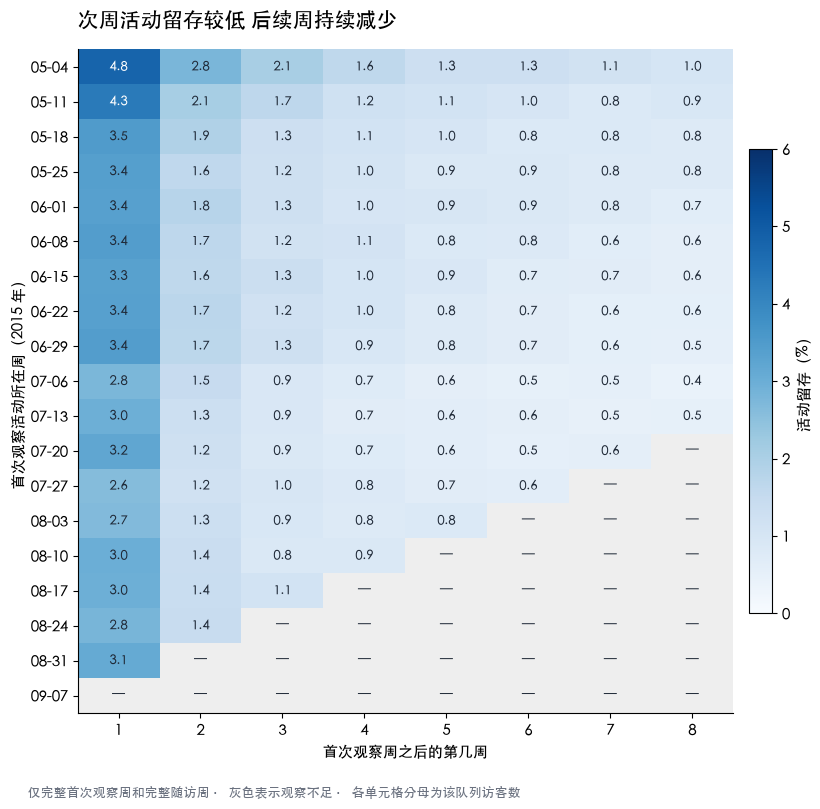

In [5]:
display(read('retention_weighted').round(3))
display(plot_results.retention())
plt.close('all')

次周留存的加权分母为 1,295,569 位访客，分子为 42,465 位。每个周龄的合格队列不同，不能把加权曲线视为同一批用户的追踪曲线。完整队列单元格已由 pandas 独立核对。

### 6 固定观察窗口的首次购买

In [6]:
display(read('06_activation').T.rename(columns={0:'值'}))

,值
observed_visitors,1.407580e+06
observed_buyers,1.171900e+04
eligible_7d_visitors,1.348273e+06
buyers_7d,1.016500e+04
activation_7d_pct,7.539274e-01
median_view_to_first_buy_hours,3.516901e-01
buyers_without_prior_view,6.090000e+02


至少有完整 7 天观察的 1,348,273 位访客中，10,165 位在首次观察后 7 天内购买，比例为 0.75%。这是首次观察活动起算的指标，不是注册激活率。

### 7 高浏览商品和行为分层

,item_id,viewing_visitors,cart_visitors,buying_visitors,buyers_after_view,view_to_cart_pct,ordered_conversion_pct
0,187946,2911,0,0,0,0.000,0.000
1,5411,2078,8,0,0,0.385,0.000
2,370653,1577,0,0,0,0.000,0.000
3,461686,1379,252,116,125,18.274,8.412
4,96924,1359,0,0,0,0.000,0.000
5,219512,1358,29,8,10,2.135,0.589
6,298009,1342,0,0,0,0.000,0.000
7,335975,1154,0,0,0,0.000,0.000
8,384302,1143,36,13,13,3.150,1.137
9,151444,1103,0,0,0,0.000,0.000


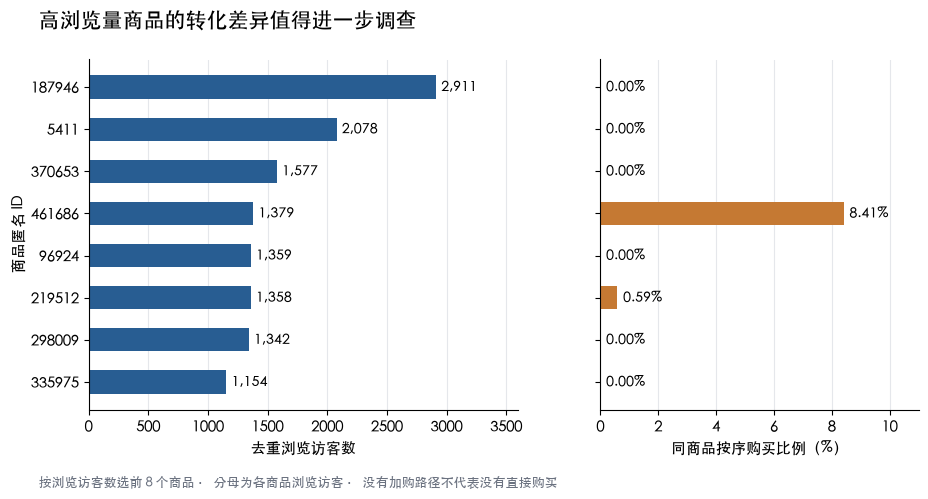

,profile,visitors,mean_active_days,mean_viewed_items,median_viewed_items,visitor_orders
0,other_no_purchase,1372954,1.15,1.41,1.0,0.0
1,cart_no_purchase,22907,1.73,3.86,2.0,0.0
2,one_order_buyer,10656,1.95,3.96,2.0,10656.0
3,repeat_buyer,1063,6.22,62.38,6.0,7016.0


In [7]:
display(read('07_products').head(10).round(3))
display(plot_results.products())
plt.close('all')
display(read('08_profiles').round(2))

### 8 高活跃访客敏感性分析

In [8]:
display(read('09_activity_sensitivity').round(3))

,population,event_threshold,visitors,viewers,ordered_carts,ordered_buyers,view_to_cart_pct,ordered_conversion_pct
0,all_visitors,47.0,1407580,1404179,32934,9952,2.345,0.709
1,exclude_above_p999,47.0,1406229,1402830,32126,9455,2.290,0.674


超过第 99.9 百分位阈值 47 条事件的 1,351 位访客暂时排除后，加购比例从 2.35% 变为 2.29%，严格顺序购买比例从 0.71% 变为 0.67%。这只是敏感性分析，不认定这些访客是机器人。

## 结论与下一步
优先调查浏览后未加购的行为路径，针对高浏览低购买商品检查可购买状态、页面说明和日志覆盖；通过真实访谈或可用性测试补充动机证据。可设计推荐模块实验，以访客随机分组、浏览后加购为主指标、购买转化与页面性能为护栏。当前只完成分析和实验方案，没有执行线上实验，也没有已实现的收入或转化提升。